In [1]:
file_name <- "PRSA_Data_Dingling_20130301-20170228.csv"

air_data <- tryCatch({

  read.csv(file_name)

}, error=function(e){

  cat("Error:",e$message,"\n")
  NULL

})

cat("First Six Records\n")
head(air_data)

cat("\nStructure\n")
str(air_data)

cat("\nRows:",nrow(air_data),"\n")

cat("Columns:",ncol(air_data),"\n")

cat("Contains Missing Values:",any(is.na(air_data)),"\n")

cat("Total Missing Values:",sum(is.na(air_data)))

First Six Records


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
,<int>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<chr>
1,1,2013,3,1,0,4,4,3,NA,200,82,-2.3,1020.8,-19.7,0,E,0.5,Dingling
2,2,2013,3,1,1,7,7,3,NA,200,80,-2.5,1021.3,-19.0,0,ENE,0.7,Dingling
3,3,2013,3,1,2,5,5,3,2,200,79,-3.0,1021.3,-19.9,0,ENE,0.2,Dingling
4,4,2013,3,1,3,6,6,3,NA,200,79,-3.6,1021.8,-19.1,0,NNE,1.0,Dingling
5,5,2013,3,1,4,5,5,3,NA,200,81,-3.5,1022.3,-19.4,0,N,2.1,Dingling
6,6,2013,3,1,5,6,6,3,4,200,79,-4.5,1022.6,-19.5,0,NNW,1.7,Dingling



Structure
'data.frame':	35064 obs. of  18 variables:
 $ No     : int  1 2 3 4 5 6 7 8 9 10 ...
 $ year   : int  2013 2013 2013 2013 2013 2013 2013 2013 2013 2013 ...
 $ month  : int  3 3 3 3 3 3 3 3 3 3 ...
 $ day    : int  1 1 1 1 1 1 1 1 1 1 ...
 $ hour   : int  0 1 2 3 4 5 6 7 8 9 ...
 $ PM2.5  : num  4 7 5 6 5 6 5 5 8 8 ...
 $ PM10   : num  4 7 5 6 5 6 10 6 7 8 ...
 $ SO2    : num  3 3 3 3 3 3 3 3 3 3 ...
 $ NO2    : num  NA NA 2 NA NA 4 4 2 3 2 ...
 $ CO     : int  200 200 200 200 200 200 200 200 200 200 ...
 $ O3     : num  82 80 79 79 81 79 77 80 79 81 ...
 $ TEMP   : num  -2.3 -2.5 -3 -3.6 -3.5 -4.5 -4.5 -2.1 -0.2 0.6 ...
 $ PRES   : num  1021 1021 1021 1022 1022 ...
 $ DEWP   : num  -19.7 -19 -19.9 -19.1 -19.4 -19.5 -19.5 -20 -20.5 -20.4 ...
 $ RAIN   : num  0 0 0 0 0 0 0 0 0 0 ...
 $ wd     : chr  "E" "ENE" "ENE" "NNE" ...
 $ WSPM   : num  0.5 0.7 0.2 1 2.1 1.7 1.8 2.5 2.8 3.8 ...
 $ station: chr  "Dingling" "Dingling" "Dingling" "Dingling" ...

Rows: 35064 
Columns: 18 
Con

In [2]:
temperature <- c(28,30,NA,32)

missing_object <- NULL

undefined_value <- 0/0

print(temperature)

print(is.na(temperature))

print(missing_object)

print(is.null(missing_object))

print(undefined_value)

print(is.nan(undefined_value))

[1] 28 30 NA 32
[1] FALSE FALSE  TRUE FALSE
NULL
[1] TRUE
[1] NaN
[1] TRUE


In [3]:
missing_summary <- function(df,variables){

result <- data.frame(
Variable=character(),
Total_Records=integer(),
Missing_Values=integer(),
Missing_Percentage=numeric()
)

for(v in variables){

total <- nrow(df)

missing <- sum(is.na(df[[v]]))

percent <- round((missing/total)*100,2)

if(percent>20){

warning(paste(v,"contains more than 20% missing values"))

}

result <- rbind(result,

data.frame(

Variable=v,

Total_Records=total,

Missing_Values=missing,

Missing_Percentage=percent

))

}

return(result)

}

selected_variables <- c("PM2.5","PM10","SO2","NO2","TEMP","WSPM","wd")

summary_table <- missing_summary(air_data,selected_variables)

summary_table

Variable,Total_Records,Missing_Values,Missing_Percentage
<chr>,<int>,<int>,<dbl>
PM2.5,35064,779,2.22
PM10,35064,656,1.87
SO2,35064,730,2.08
NO2,35064,1234,3.52
TEMP,35064,53,0.15
WSPM,35064,43,0.12
wd,35064,140,0.40


In [4]:
air_data$pollution_ratio <- air_data$PM2.5 / air_data$PM10

cat("NA:",sum(is.na(air_data$pollution_ratio)),"\n")

cat("NaN:",sum(is.nan(air_data$pollution_ratio)),"\n")

cat("Infinite:",sum(is.infinite(air_data$pollution_ratio)),"\n")

air_data$pollution_ratio[

is.nan(air_data$pollution_ratio) |

is.infinite(air_data$pollution_ratio)

] <- NA

NA: 807 
NaN: 0 
Infinite: 0 


In [5]:
numeric_variables <- c("PM2.5","PM10","SO2","NO2","TEMP","WSPM")

before_missing <- c()

after_missing <- c()

for(v in numeric_variables){

if(v %in% names(air_data)){

before <- sum(is.na(air_data[[v]]))

median_value <- median(air_data[[v]],na.rm=TRUE)

air_data[[v]][is.na(air_data[[v]])] <- median_value

after <- sum(is.na(air_data[[v]]))

before_missing <- c(before_missing,before)

after_missing <- c(after_missing,after)

cat("\nVariable:",v)

cat("\nMissing Before:",before)

cat("\nMedian:",median_value)

cat("\nMissing After:",after,"\n")

}

}


Variable: PM2.5
Missing Before: 779
Median: 41
Missing After: 0 

Variable: PM10
Missing Before: 656
Median: 60
Missing After: 0 

Variable: SO2
Missing Before: 730
Median: 5
Missing After: 0 

Variable: NO2
Missing Before: 1234
Median: 19
Missing After: 0 

Variable: TEMP
Missing Before: 53
Median: 14.7
Missing After: 0 

Variable: WSPM
Missing Before: 43
Median: 1.5
Missing After: 0 


In [6]:
calculate_mode <- function(x){

unique_values <- unique(x[!is.na(x)])

unique_values[which.max(tabulate(match(x,unique_values)))]

}

before_wd <- sum(is.na(air_data$wd))

mode_wd <- calculate_mode(air_data$wd)

air_data$wd[is.na(air_data$wd)] <- mode_wd

after_wd <- sum(is.na(air_data$wd))

cat("Mode:",mode_wd,"\n")

cat("Missing Before:",before_wd,"\n")

cat("Missing After:",after_wd)

Mode: NNW 
Missing Before: 140 
Missing After: 0

In [7]:
clean_variable <- function(df,var){

tryCatch({

if(!(var %in% names(df)))

stop("Variable does not exist.")

if(!is.numeric(df[[var]]))

stop("Variable is not numerical.")

if(all(is.na(df[[var]])))

stop("Variable contains only missing values.")

med <- median(df[[var]],na.rm=TRUE)

if(is.na(med))

stop("Median cannot be calculated.")

df[[var]][is.na(df[[var]])] <- med

return(df[[var]])

},

error=function(e){

cat("Error:",e$message,"\n")

return(NULL)

})

}

clean_variable(air_data,"PM2.5")

clean_variable(air_data,"wd")

clean_variable(air_data,"XYZ")

[1]   4.0   7.0   5.0   6.0   5.0   6.0   5.0   5.0   8.0   8.0   8.0   3.0
   [13]   6.0   7.0   6.0  10.0   3.0   5.0   5.0  14.0   6.0   9.0   6.0   6.0
   [25]   4.0   6.0   7.0  28.0  31.0  39.0  41.0  52.0  36.0  27.0  29.0  19.0
   [37]  28.0  30.0  26.0  32.0  39.0  43.0  48.0  46.0  45.0  50.0  56.0  55.0
   [49]  60.0  59.0  52.0  57.0  53.0  48.0  53.0  53.0  50.0  60.0  73.0  76.0
   [61]  75.0  92.0  79.0  44.0  14.0   5.0   3.0  11.0   5.0  12.0   4.0  14.0
   [73]  13.0  10.0   8.0   5.0  11.0   5.0   8.0   7.0   4.0   5.0   8.0   7.0
   [85]   5.0  10.0  13.0  16.0  18.0  18.0  10.0  39.0  41.0  60.0  50.0  50.0
   [97]  52.0  56.0  50.0  88.0  53.0  46.0  43.0  47.0  52.0  52.0  69.0  79.0
  [109] 102.0 126.0 131.0 139.0 152.0 154.0 165.0 179.0 172.0 179.0 173.0 170.0
  [121] 166.0 173.0 161.0 161.0 163.0 166.0 172.0 176.0 183.0 195.0 200.0 217.0
  [133] 268.0 258.0 221.0 195.0 294.0 288.0 267.0 269.0 280.0 306.0 284.0 236.0
  [145] 223.0 196.0 150.0  91.0  61.0  50.0  26.0  19.0  33.0  28.0  47.0 134.0
  [157] 224.0 153.0  74.0  75.0 149.0 223.0 258.0 244.0 253.0 240.0 224.0 219.0
  [169] 189.0 248.0 167.0 137.0 133.0  79.0  41.0  37.0  38.0  48.0 122.0 166.0
  [181] 108.0 111.0 146.0 410.0 405.0 190.0 173.0 118.0 120.0 113.0 104.0 105.0
  [193] 108.0 111.0 110.0 194.0 101.0 106.0  54.0  99.0 118.0 165.0  72.0  22.0
  [205]  29.0  32.0  24.0  16.0  15.0   8.0   3.0  10.0  10.0  13.0  13.0   3.0
  [217]   7.0  12.0  13.0  10.0  13.0   8.0  10.0   8.0  11.0  18.0   7.0  12.0
  [229]  16.0  16.0  21.0  30.0  33.0  37.0  42.0  53.0  61.0  56.0  62.0  63.0
  [241]  68.0  68.0  69.0  75.0  79.0  83.0  85.0  80.0  89.0 107.0 108.0 112.0
  [253] 113.0 132.0 130.0 148.0 149.0 152.0 149.0 152.0 166.0 175.0 173.0 163.0
  [265] 156.0 150.0 150.0 134.0 127.0 135.0 128.0 123.0 121.0 116.0 114.0 132.0
  [277] 145.0 158.0 172.0 176.0 171.0 213.0 221.0 211.0 186.0  59.0   6.0  10.0
  [289]   3.0   7.0   9.0   3.0   3.0  12.0   9.0   3.0   3.0  10.0  10.0   3.0
  [301]   3.0   3.0  13.0   8.0  12.0  15.0  18.0  22.0  27.0   7.0  25.0  35.0
  [313]  41.0  44.0  44.0  47.0  67.0  74.0  73.0  72.0  83.0  95.0 104.0 132.0
  [325] 140.0 130.0 136.0 146.0 151.0 146.0 142.0 137.0 138.0 153.0 150.0 143.0
  [337] 150.0 149.0 154.0 148.0 151.0 148.0 148.0 150.0 174.0 174.0 175.0 215.0
  [349] 212.0 213.0 221.0 223.0 237.0 254.0 262.0 260.0 261.0 270.0 262.0 289.0
  [361] 272.0 268.0 270.0 273.0 267.0 253.0 242.0 240.0 258.0 252.0 282.0 290.0
  [373] 197.0 154.0 174.0 179.0 166.0 165.0 208.0 225.0 269.0 268.0 260.0 268.0
  [385] 271.0 282.0 286.0 283.0 286.0 274.0 257.0 247.0 257.0 311.0 324.0 304.0
  [397] 317.0 335.0 350.0 371.0 379.0 390.0 393.0 393.0 381.0 380.0 388.0 377.0
  [409] 370.0  48.0  24.0  11.0   9.0  11.0  16.0   8.0  10.0   3.0   9.0   6.0
  [421]   8.0   8.0   7.0  15.0   8.0  12.0  17.0  30.0  45.0  46.0  44.0  44.0
  [433]  43.0  41.0  36.0  40.0  29.0  43.0  43.0  40.0  48.0  42.0  53.0  64.0
  [445]  63.0  65.0  66.0  57.0  40.0  29.0  31.0  38.0  42.0  44.0  41.0  42.0
  [457]  16.0  22.0  30.0  14.0  14.0  14.0  10.0  11.0   8.0  17.0  18.0  22.0
  [469]  22.0  16.0  18.0  24.0  30.0  44.0  50.0  63.0  62.0  65.0  73.0  82.0
  [481]  88.0  90.0  94.0 100.0 112.0 115.0 108.0 106.0 107.0 121.0 117.0 141.0
  [493] 145.0 130.0 142.0 158.0 166.0 170.0 168.0 162.0 170.0 169.0 156.0 148.0
  [505]  43.0   6.0   7.0   7.0 120.0   3.0   4.0   8.0   9.0  94.0  90.0  84.0
  [517]  18.0  25.0  48.0  68.0 107.0  93.0  84.0  91.0  89.0  83.0  79.0  65.0
  [529]  53.0  52.0  60.0  56.0  51.0  52.0  55.0  68.0  70.0  71.0  74.0  70.0
  [541]  74.0  98.0 110.0 109.0  44.0   8.0  12.0   5.0   7.0   9.0   6.0   5.0
  [553]   6.0   5.0   5.0   4.0   8.0   9.0   4.0   7.0   8.0   6.0   9.0   3.0
  [565]  11.0  10.0  14.0  11.0  15.0  16.0  18.0  26.0  36.0  39.0  31.0  28.0
  [577]  28.0  31.0  31.0  37.0  39.0  50.0  59.0  60.0  86.0  77.0  84.0  96.0
  [589] 106.0 111.0 104.0 117.0 123.0 123.0 131.0 124.0 130.0 119.0 119.0 129.0
  [6

Error: Variable is not numerical. 


NULL

Error: Variable does not exist. 


NULL

In [8]:
comparison <- data.frame(

Variable=c(numeric_variables,"wd"),

Missing_Before=c(before_missing,before_wd),

Missing_After=c(after_missing,after_wd)

)

comparison$Values_Replaced <-

comparison$Missing_Before -

comparison$Missing_After

comparison

Variable,Missing_Before,Missing_After,Values_Replaced
<chr>,<int>,<int>,<int>
PM2.5,779,0,779
PM10,656,0,656
SO2,730,0,730
NO2,1234,0,1234
TEMP,53,0,53
WSPM,43,0,43
wd,140,0,140


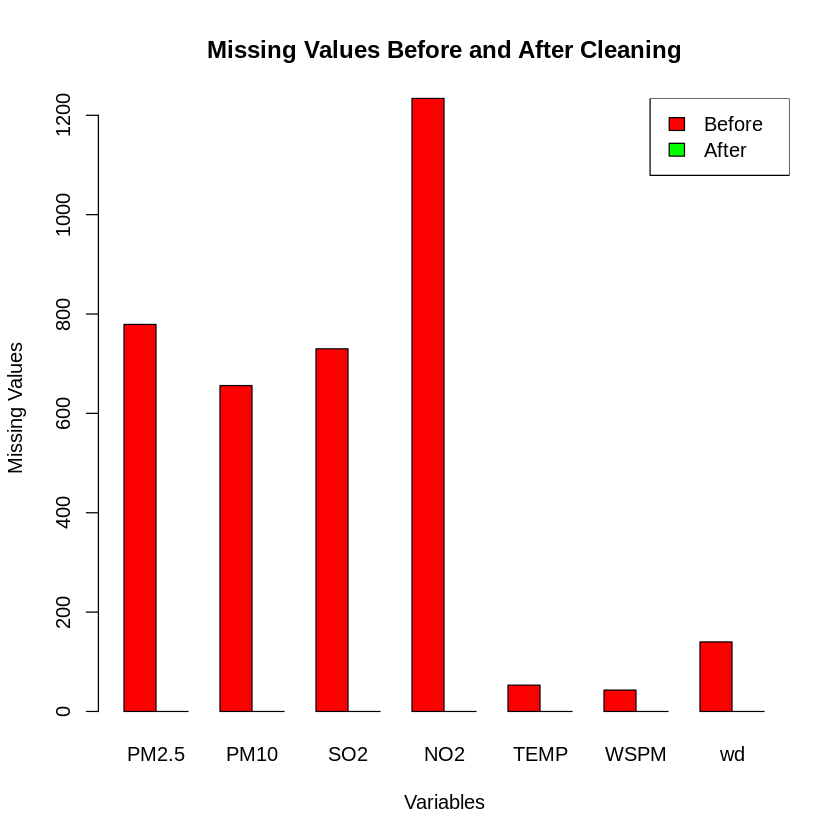

In [9]:
barplot(

rbind(

comparison$Missing_Before,

comparison$Missing_After

),

beside=TRUE,

col=c("red","green"),

names.arg=comparison$Variable,

main="Missing Values Before and After Cleaning",

xlab="Variables",

ylab="Missing Values"

)

legend(

"topright",

legend=c("Before","After"),

fill=c("red","green")

)

In [10]:
write.csv(

air_data,

"cleaned_air_quality_data.csv",

row.names=FALSE

)

cat("Cleaned dataset exported successfully.")

Cleaned dataset exported successfully.

The Beijing Air Quality dataset contained missing values in several pollutant and weather variables. The missing values were identified and summarized using a user-defined function. Numerical variables such as PM2.5, PM10, SO2, NO2, TEMP, and WSPM were cleaned by replacing missing values with their respective median values, while missing values in the categorical variable wd were replaced using the mode. Invalid values such as NaN and infinite values in the pollution_ratio variable were converted to NA. Error handling using tryCatch() ensured that invalid file names and variables did not stop the execution of the program. A comparison table and bar chart confirmed that the selected missing values were successfully handled. Finally, the cleaned dataset was exported successfully for further air-quality analysis.